# Analítica de Datos para la Detección Temprana del Riesgo Cardiovascular

## Introducción
En este proyecto, exploramos un conjunto de datos que recopila diversas métricas de salud de pacientes cardíacos, como edad, presión arterial, frecuencia cardíaca, entre otras. Nuestro objetivo es desarrollar un modelo predictivo capaz de identificar con precisión a personas con enfermedades cardíacas. Dadas las graves implicaciones de no detectar un diagnóstico positivo, nuestro principal énfasis radica en garantizar que el modelo identifique a todos los pacientes potenciales, por lo que la exhaustividad (recall) para la clase positiva constituye una métrica crucial.

## Objetivos

* **Explorar el conjunto de datos:** Descubrir patrones, distribuciones y relaciones dentro de los datos.
* **Realizar un análisis exploratorio de datos (EDA) exhaustivo:** Analizar en profundidad las relaciones bivariadas respecto a la variable objetivo.

**Pasos de preprocesamiento:**
*  Eliminar características irrelevantes.
* Tratar los valores faltantes.
* Manejar los valores atípicos.
* Codificar las variables categóricas.
* Transformar las características con asimetría para aproximarlas a distribuciones normales.

**Construcción de modelos:**
* Establecer *pipelines* para aquellos modelos que requieran escalado.
* Implementar y ajustar modelos de clasificación, árboles de decisión y Random Forest.
* Priorizar un alto *recall* (exhaustividad) para la clase 1, garantizando una identificación exhaustiva de los pacientes cardíacos.


**Evaluar y comparar el rendimiento de los modelos:** Utilizar precisión (*precision*), exhaustividad (*recall*) y puntuación F1 (*F1-score*) para medir la efectividad de cada modelo.

# 1. | Importación de Librerías

In [1]:
import numpy as np
import pandas as pd

# Modelos
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Procesamiento y Evaluación
from scipy.stats import boxcox
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

# Gráficos y estilos visuales
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

%matplotlib inline

In [2]:
# Establecer la resolución de las figuras generadas
plt.rcParams['figure.dpi'] = 200

# Configurar el estilo de Seaborn: fondo azul clínico claro con cuadrícula oscura
sns.set_theme(
    style='darkgrid',
    rc={
        'axes.facecolor': '#EBF2F7',   # Azul hielo/clínico muy suave para el área del gráfico
        'figure.facecolor': '#F4F8FA', # Tono casi blanco con matiz azul para el lienzo exterior
        'grid.color': '#D0DEE9'        # Líneas de cuadrícula en azul grisáceo tenue
    }
)

# 2. | Lectura de Datos

In [3]:
# Leer dataset
df = pd.read_csv('https://raw.githubusercontent.com/david-ramirezl/data/refs/heads/main/heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## Descripción de Características

| Variable | Descripción |
| :--- | :--- |
| `age` | Edad del paciente en años. |
| `sex` | Sexo del paciente (0 = hombre, 1 = mujer). |
| `cp` | Tipo de dolor torácico:<br>• 0: Angina típica<br>• 1: Angina atípica<br>• 2: Dolor no anginoso<br>• 3: Asintomático |
| `trestbps` | Presión arterial en reposo (en mm Hg al ingresar al hospital). |
| `chol` | Colesterol sérico en mg/dl. |
| `fbs` | Nivel de glucosa en ayunas mayor a 120 mg/dl (1 = verdadero, 0 = falso). |
| `restecg` | Resultados electrocardiográficos en reposo:<br>• 0: Normal<br>• 1: Con anomalía de la onda ST-T<br>• 2: Con hipertrofia ventricular izquierda probable o definitiva |
| `thalach` | Frecuencia cardíaca máxima alcanzada durante la prueba de esfuerzo. |
| `exang` | Angina inducida por el ejercicio (1 = sí, 0 = no). |
| `oldpeak` | Depresión del ST inducida por el esfuerzo en relación con el reposo. |
| `slope` | Pendiente del segmento ST durante el pico de esfuerzo:<br>• 0: Ascendente<br>• 1: Plana<br>• 2: Descendente |
| `ca` | Número de vasos mayores (0-4) coloreados por fluoroscopía. |
| `thal` | Resultado de la prueba de esfuerzo con talio:<br>• 0: Normal<br>• 1: Defecto fijo<br>• 2: Defecto reversible<br>• 3: No descrito |
| `target` | Presencia de enfermedad cardíaca (0 = sin enfermedad, 1 = presencia de enfermedad). |

# 3. | Descripción General del Conjunto

## 3.1 | Información Básica del Conjunto

In [4]:
# Mostrar un resumen conciso del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


### Observaciones:
- **Número de registros:** El conjunto de datos contiene 1025 entradas, con índices del 0 al 1024.
- **Columnas:** Existen 14 columnas que corresponden a diversos atributos de los pacientes y resultados de pruebas clínicas.
- **Tipos de datos:**
  - La mayoría de las columnas (13 de 14) corresponden al tipo de dato `int64`.
  - Solo la columna `oldpeak` es de tipo `float64`.
- **Valores nulos:** No se observan valores faltantes en el conjunto de datos, ya que cada columna cuenta con 1025 entradas no nulas (*non-null*).

> **Nota:** Según los tipos de datos y las explicaciones de las características revisadas anteriormente, se observa que 9 columnas (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal` y `target`) son numéricas a nivel de tipo de dato, pero categóricas en cuanto a su semántica. Estas variables deben convertirse al tipo de dato cadena (`object` o `str`) para permitir un análisis y una interpretación adecuados:

In [5]:
# Definir las características continuas
caracteristicas_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# Identificar las características que se deben convertir al tipo de dato object
caracteristicas_a_convertir = [columna for columna in df.columns if columna not in caracteristicas_continuas]

# Convertir las características identificadas al tipo de dato object
df[caracteristicas_a_convertir] = df[caracteristicas_a_convertir].astype('object')

df.dtypes

age           int64
sex          object
cp           object
trestbps      int64
chol          int64
fbs          object
restecg      object
thalach       int64
exang        object
oldpeak     float64
slope        object
ca           object
thal         object
target       object
dtype: object

## 3.2 | Estadísticas descriptivas de las variables numéricas

Analicemos las estadísticas descriptivas de nuestras variables numéricas:

In [6]:
# Obtener las estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


### Variables numéricas:
- **`age`:** La edad promedio de los pacientes es de aproximadamente 54.4 años, con un mínimo de 29 y un máximo de 77 años.
- **`trestbps`:** La presión arterial en reposo promedio es de cerca de 131.61 mm Hg, con un rango que va de 94 a 200 mm Hg.
- **`chol`:** El nivel promedio de colesterol es de aproximadamente 246 mg/dl, con un mínimo de 126 y un máximo de 564 mg/dl.
- **`thalach`:** La frecuencia cardíaca máxima alcanzada promedio se sitúa alrededor de 149.11 lpm, en un rango de 71 a 202.
- **`oldpeak`:** La depresión del ST promedio inducida por el ejercicio en relación con el reposo es de cerca de 1.07, con valores que oscilan entre 0 y 6.2.

## 3.3 | Estadísticas descriptivas de las variables categóricas

A continuación, revisemos las estadísticas descriptivas de las características categóricas:

In [7]:
# Obtener las estadísticas descriptivas de las variables categóricas
df.describe(include='object')

,sex,cp,fbs,restecg,exang,slope,ca,thal,target
count,1025,1025,1025,1025,1025,1025,1025,1025,1025
unique,2,4,2,3,2,3,5,4,2
top,1,0,0,1,0,1,0,2,1
freq,713,497,872,513,680,482,578,544,526


### Variables categóricas (tipo de dato object):
- **`sex`:** Presenta dos valores únicos, siendo los hombres (identificados como 1) la categoría más frecuente, con 713 apariciones de un total de 1025 registros.
- **`cp`:** Se registran cuatro tipos de dolor torácico. El más común es el tipo "0", con 497 ocurrencias.
- **`fbs`:** Consta de dos categorías; la más frecuente es "0" (indica glucosa en ayunas menor a 120 mg/dl), presente en 872 ocasiones.
- **`restecg`:** Incluye tres resultados electrocardiográficos posibles. El más frecuente es "1", observado en 513 registros.
- **`exang`:** Posee dos valores únicos. El valor predominante es "0" (indica ausencia de angina inducida por ejercicio), registrado 680 veces.
- **`slope`:** Muestra tres tipos de pendiente del segmento ST. La más habitual es la categoría "1", presente en 482 casos.
- **`ca`:** Contiene cinco valores para el número de vasos principales teñidos por fluoroscopía, donde "0" es el más frecuente, registrado en 578 pacientes.
- **`thal`:** Dispone de cuatro resultados posibles de la prueba de talio. El tipo predominante es "2" (defecto reversible), identificado en 544 registros.
- **`target`:** Cuenta con dos valores que señalan la presencia o ausencia de enfermedad cardíaca. El valor "1" (presencia de cardiopatía) es el más frecuente, registrado en 526 pacientes.

# 4. | EDA

Para nuestro Análisis Exploratorio de Datos (EDA), avanzaremos en dos etapas principales:

1. **Análisis univariado:** Nos enfocaremos en una característica a la vez para comprender su distribución y rango de valores.
2. **Análisis bivariado:** Exploraremos la relación entre cada característica y la variable objetivo (*target*). Esto permite evaluar la importancia e influencia de cada variable sobre el resultado que buscamos predecir.

Con estas dos etapas, el propósito es obtener una visión clara tanto de las características individuales de los datos como de su vínculo con el objetivo central: predecir la variable objetivo.

## 4.1 | Análisis univariado

Realizamos el análisis univariado de las características del conjunto de datos en función de su tipo de dato:

- **Para datos continuos:** Empleamos histogramas para analizar la distribución de cada característica. Esto nos permite comprender la tendencia central, la dispersión y la forma de la distribución en los datos.
- **Para datos categóricos:** Utilizamos gráficos de barras para visualizar la frecuencia de cada categoría, proporcionando una representación clara del peso o predominio de cada categoría dentro de la variable analizada.

A través de estas técnicas de visualización, logramos una mejor comprensión de las propiedades individuales de cada variable en el conjunto de datos.

### 4.1.1 | Análisis univariado de variables numéricas

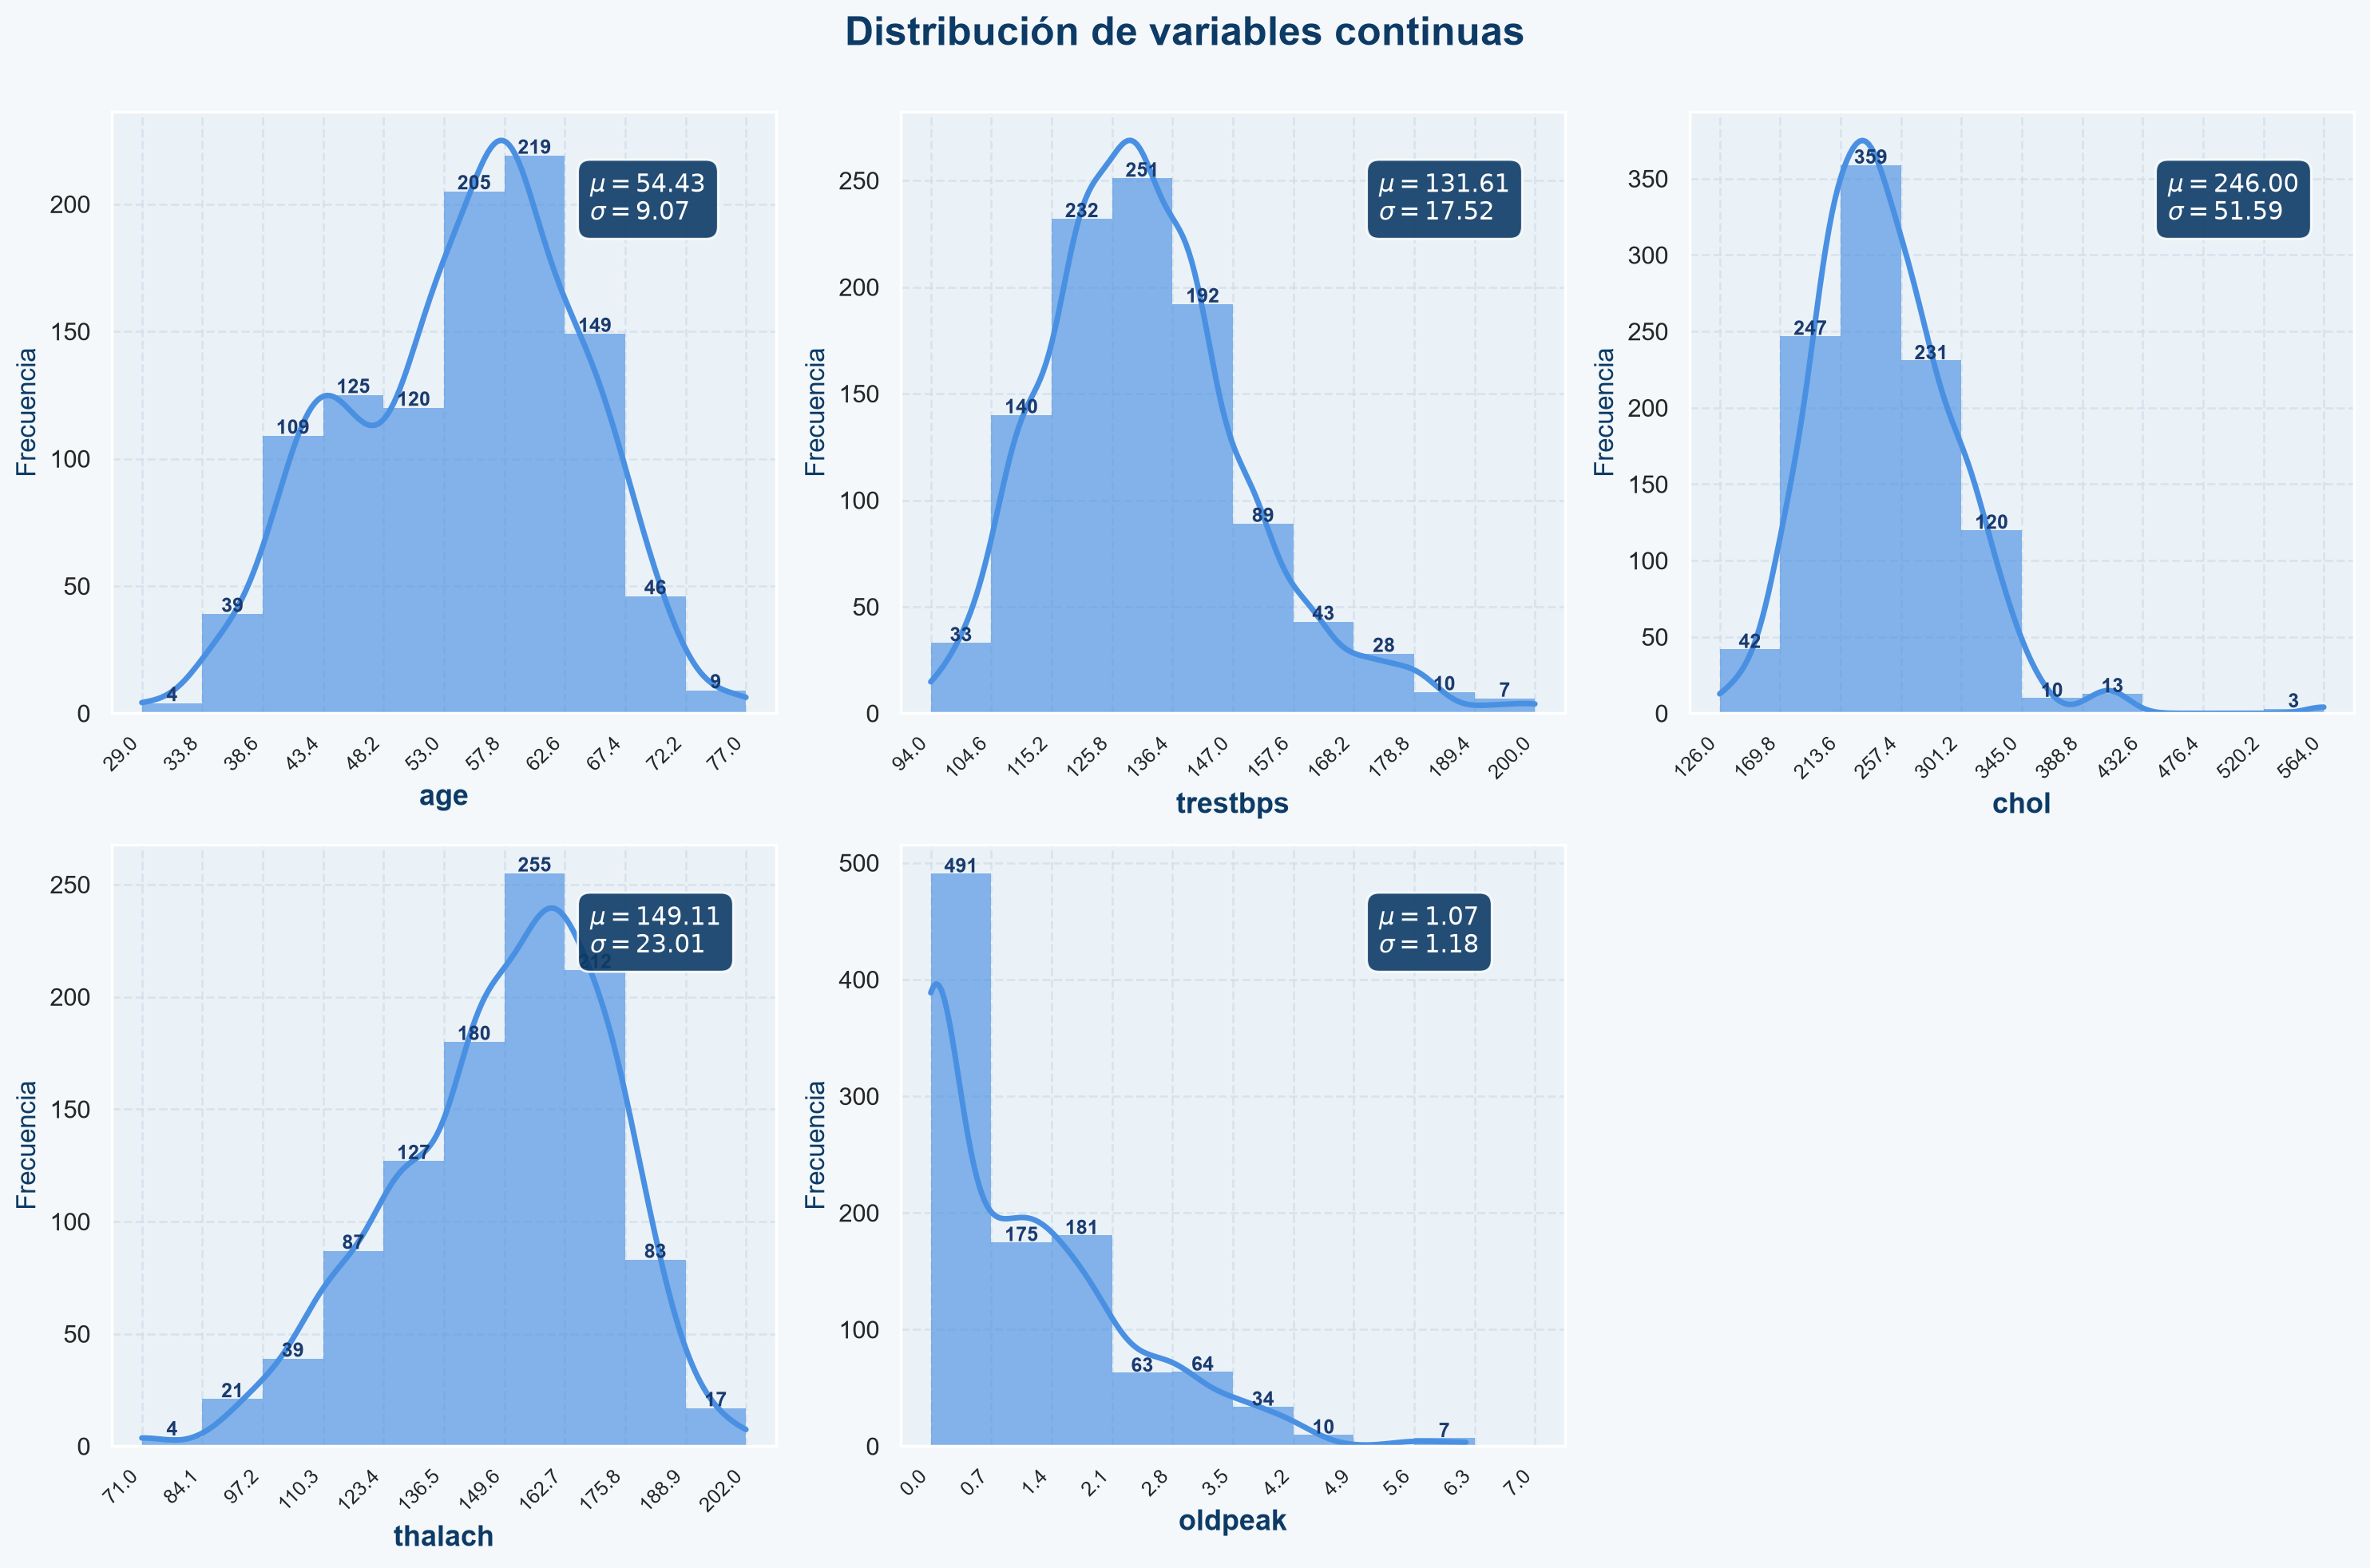

In [8]:
# Filtrar características continuas para el análisis univariado
df_continuas = df[caracteristicas_continuas]

# Configurar la cuadrícula de subgráficos
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))

# Iterar para graficar histogramas de cada característica continua
for i, col in enumerate(df_continuas.columns):
    x = i // 3
    y = i % 3
    valores, bordes_bins = np.histogram(
        df_continuas[col], 
        range=(np.floor(df_continuas[col].min()), np.ceil(df_continuas[col].max()))
    )
    
    # Gráfico con azul clínico intermedio (#4A90E2) y línea KDE en azul marino profundo (#0D3B66)
    grafico = sns.histplot(
        data=df_continuas, 
        x=col, 
        bins=bordes_bins, 
        kde=True, 
        ax=ax[x, y],
        edgecolor='none', 
        color='#4A90E2', 
        alpha=0.65, 
        line_kws={'lw': 2.5, 'color': '#0D3B66'}
    )
    
    ax[x, y].set_facecolor('#EBF2F7')
    ax[x, y].set_xlabel(col, fontsize=13, fontweight='bold', color='#0D3B66')
    ax[x, y].set_ylabel('Frecuencia', fontsize=12, color='#0D3B66')
    ax[x, y].set_xticks(np.round(bordes_bins, 1))
    ax[x, y].set_xticklabels(ax[x, y].get_xticks(), rotation=45, ha='right', fontsize=9)
    ax[x, y].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7)
    
    # Anotaciones de frecuencia sobre cada barra
    for j, p in enumerate(grafico.patches):
        altura = p.get_height()
        if altura > 0:
            ax[x, y].annotate(
                f'{int(altura)}', 
                (p.get_x() + p.get_width() / 2, altura + 0.8),
                ha='center', 
                fontsize=9, 
                fontweight='bold',
                color='#1B3B6F'
            )
    
    # Cuadro de estadísticas (media y desviación estándar) en tono azul marino clínico
    texto_estadisticas = '\n'.join((
        r'$\mu=%.2f$' % df_continuas[col].mean(),
        r'$\sigma=%.2f$' % df_continuas[col].std()
    ))
    ax[x, y].text(
        0.72, 0.90, 
        texto_estadisticas, 
        transform=ax[x, y].transAxes, 
        fontsize=11, 
        verticalalignment='top',
        color='white', 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#0D3B66', edgecolor='white', alpha=0.9)
    )

# Desactivar el último eje vacío
ax[1, 2].axis('off')

fig.patch.set_facecolor('#F4F8FA')
plt.suptitle('Distribución de variables continuas', fontsize=18, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

### Observaciones:
- **Edad (`age`):** La distribución es moderadamente uniforme, aunque presenta una mayor concentración hacia finales de los 50 años. La edad media es de aproximadamente 54.43 años, con una desviación estándar de 9.07 años.
- **Presión arterial en reposo (`trestbps`):** Para la mayoría de los individuos, los valores se concentran entre 120 y 140 mm Hg, con un promedio de cerca de 131.62 mm Hg y una desviación estándar de 17.54 mm Hg.
- **Colesterol sérico (`chol`):** La mayoría de los pacientes registra niveles de colesterol situados entre 200 y 300 mg/dl. El promedio alcanza alrededor de 246.26 mg/dl, con una desviación estándar de 51.83 mg/dl.
- **Frecuencia cardíaca máxima alcanzada (`thalach`):** Gran parte de los individuos alcanza frecuencias de entre 140 y 170 lpm durante la prueba de esfuerzo. El valor promedio se sitúa en torno a 149.65 lpm, con una desviación estándar de 22.91 lpm.
- **Depresión del ST inducida por esfuerzo (`oldpeak`):** La mayoría de los valores se concentra cerca de 0, lo que evidencia que un número significativo de pacientes no experimentó una depresión marcada del segmento ST durante la prueba de ejercicio. El valor promedio es de 1.04, con una desviación estándar de 1.16.

Al examinar los histogramas de las variables continuas y contrastarlos con las descripciones clínicas de referencia, las distribuciones se muestran consistentes y dentro de los rangos fisiológicos esperados. No se observan anomalías graves, ruido evidente ni registros inverosímiles entre estas variables cuantitativas.

### 4.1.2 | Análisis univariado de variables categóricas

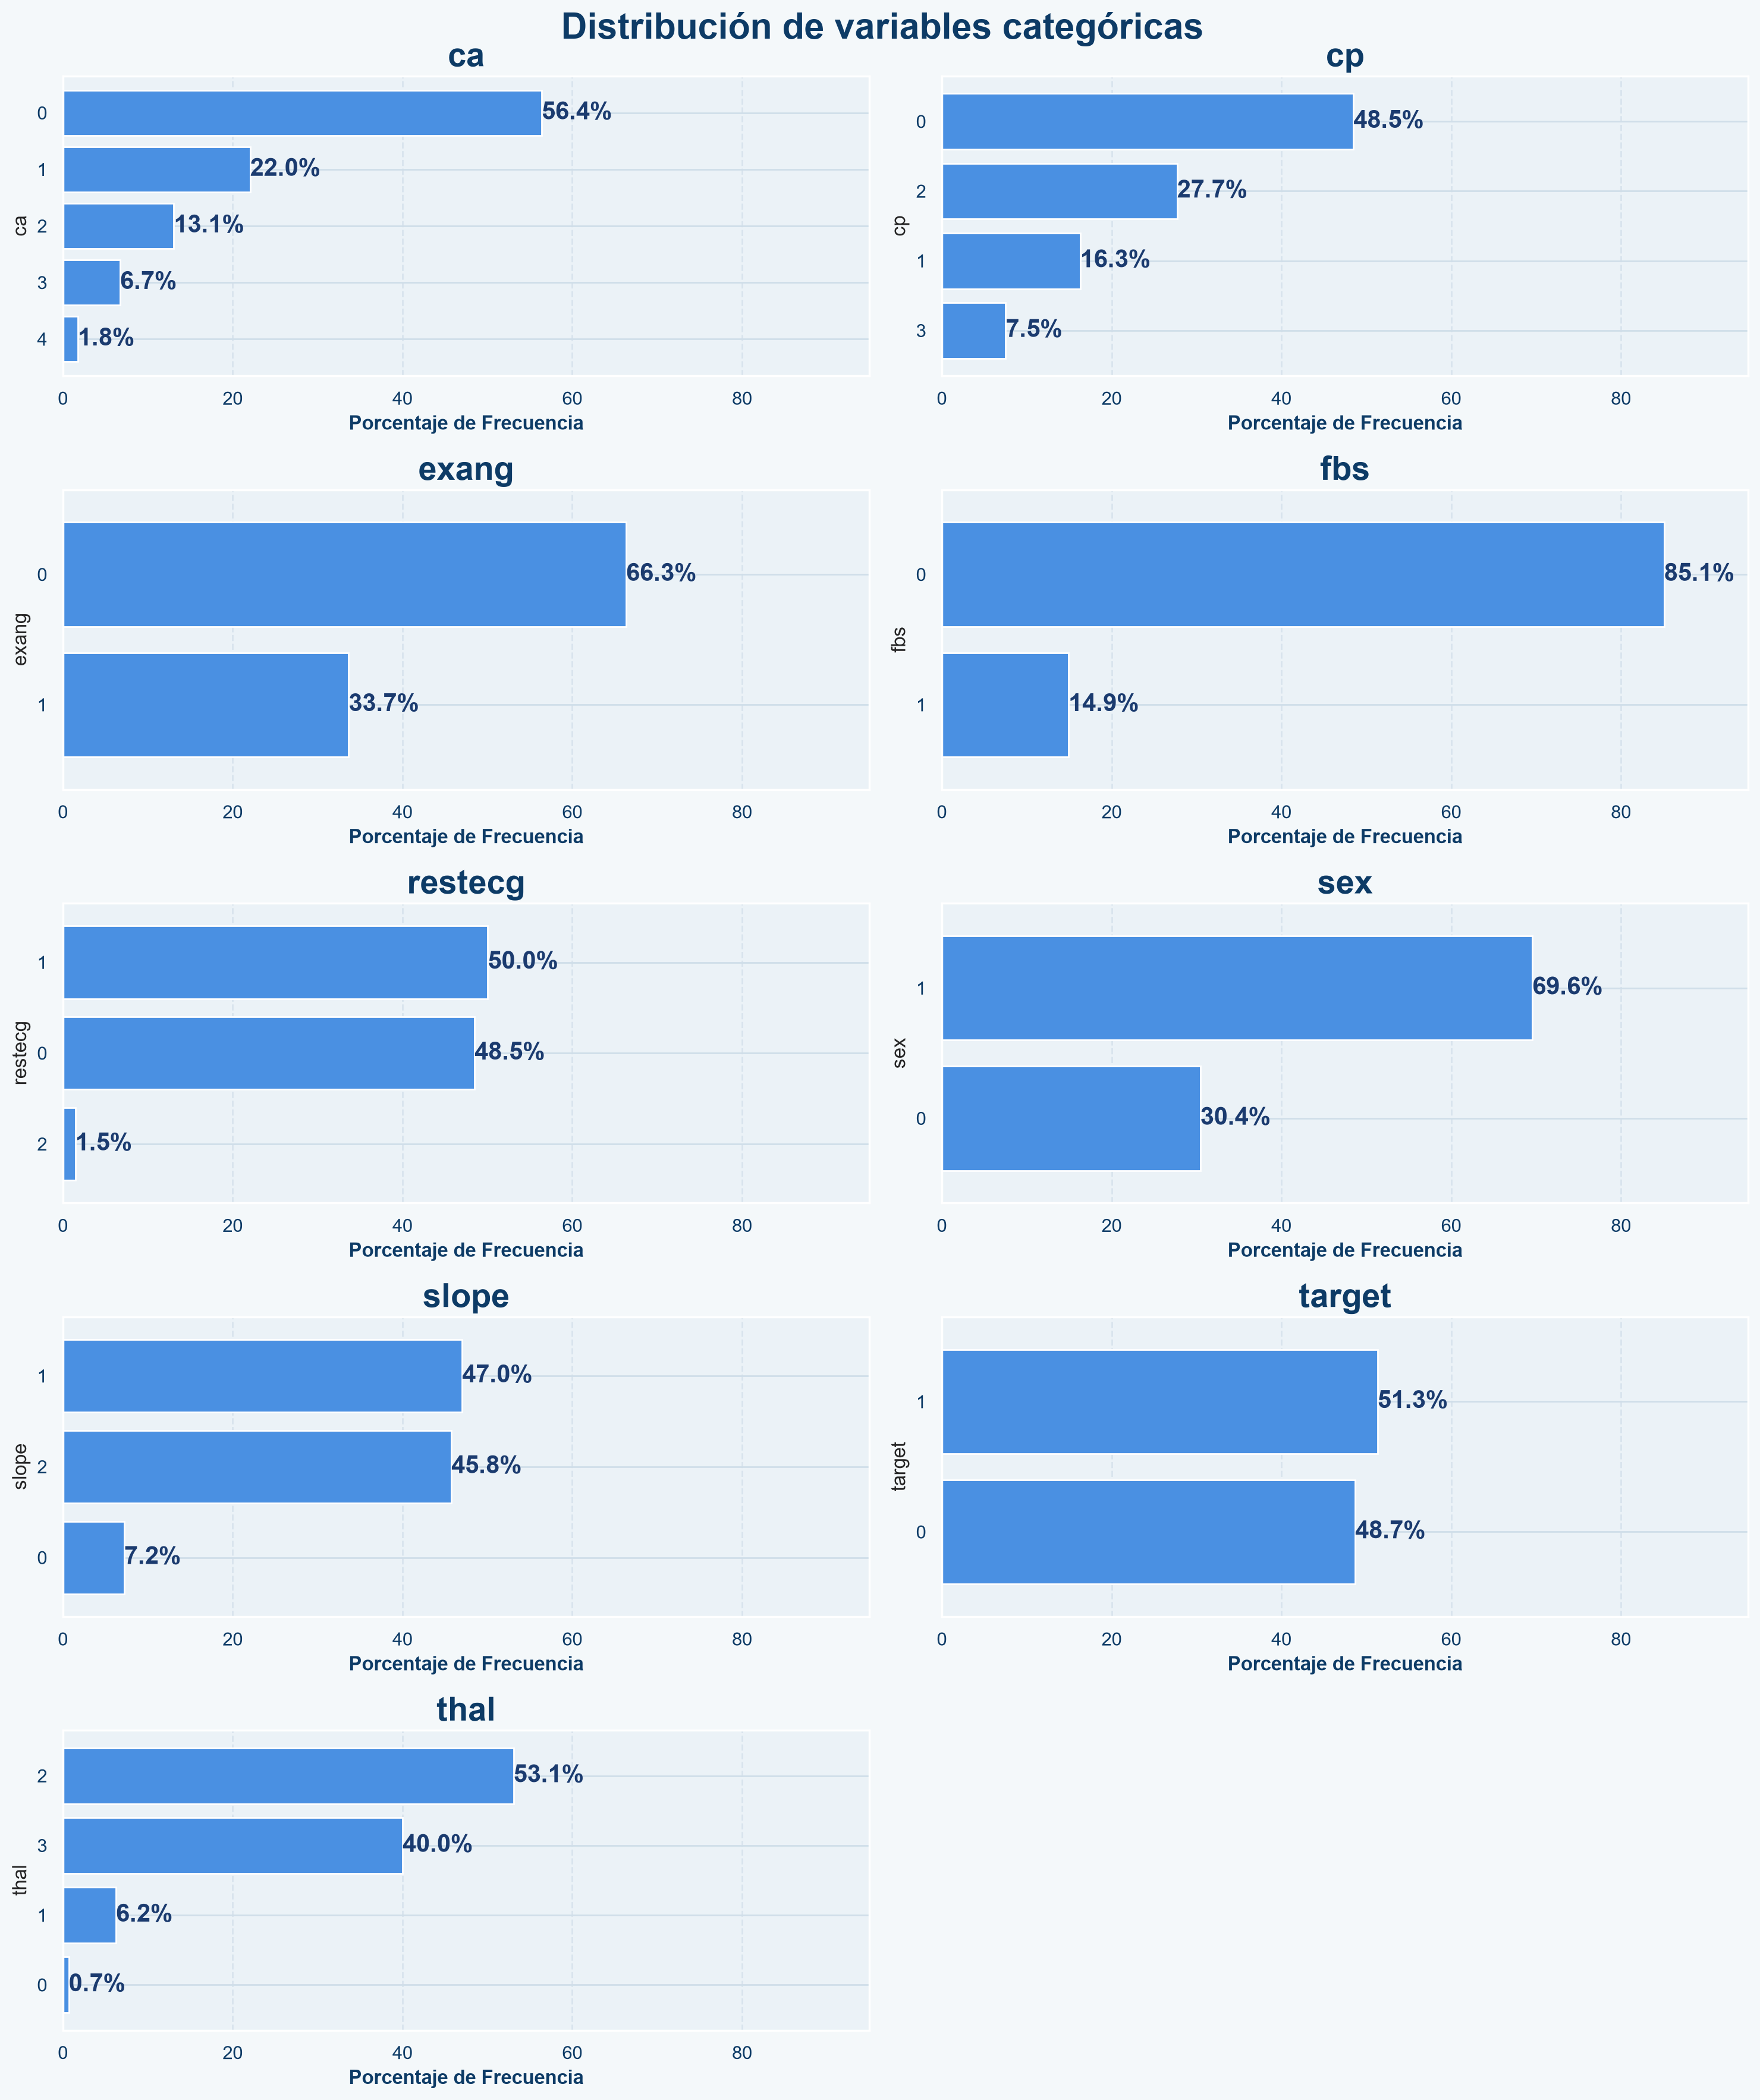

In [9]:
# Filtrar características categóricas para el análisis univariado
caracteristicas_categoricas = df.columns.difference(caracteristicas_continuas)
df_categoricas = df[caracteristicas_categoricas]

# Configurar la cuadrícula de subgráficos para un diseño de 5x2
fig, ax = plt.subplots(nrows=5, ncols=2, figsize=(15, 18))

# Aplicar color de fondo a la figura completa
fig.patch.set_facecolor('#F4F8FA')

# Iterar para graficar gráficos de barras horizontales para cada característica categórica
for i, col in enumerate(caracteristicas_categoricas):
    row = i // 2
    col_idx = i % 2
    
    # Calcular porcentajes de frecuencia
    conteo_valores = df[col].value_counts(normalize=True).mul(100).sort_values()
    
    # Graficar gráfico de barras usando el color azul clínico intermedio (#4A90E2)
    conteo_valores.plot(kind='barh', ax=ax[row, col_idx], width=0.8, color='#4A90E2')
    
    # Configurar color de fondo del gráfico y la cuadrícula
    ax[row, col_idx].set_facecolor('#EBF2F7')
    ax[row, col_idx].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7, axis='x')
    
    # Añadir porcentajes de frecuencia a las barras con el color de texto respectivo (#1B3B6F)
    for index, value in enumerate(conteo_valores):
        ax[row, col_idx].text(
            value, index, str(round(value, 1)) + '%', 
            fontsize=15, weight='bold', va='center', color='#1B3B6F'
        )
    
    # Configuración de los ejes y títulos usando azul marino profundo (#0D3B66)
    ax[row, col_idx].set_xlim([0, 95])
    ax[row, col_idx].set_xlabel('Porcentaje de Frecuencia', fontsize=12, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].set_title(f'{col}', fontsize=20, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].tick_params(colors='#0D3B66')

# Desactivar el último eje vacío
ax[4, 1].axis('off')

# Título principal de la figura
plt.suptitle('Distribución de variables categóricas', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

### Observaciones:
* **Género (`sex`):** El conjunto de datos es predominantemente femenino, constituyendo una mayoría significativa.
* **Tipo de dolor en el pecho (`cp`):** El conjunto de datos muestra variados tipos de dolor en el pecho entre los pacientes. El tipo 0 (angina típica) parece ser el más prevalente, pero la distribución exacta entre los tipos se puede inferir de los gráficos de barras.
* **Azúcar en sangre en ayunas (`fbs`):** Una gran mayoría de los pacientes tiene su nivel de azúcar en sangre en ayunas por debajo de 120 mg/dl, lo que indica que el nivel alto de azúcar en sangre no es una condición común en este conjunto de datos.
* **Resultados electrocardiográficos en reposo (`restecg`):** Los resultados muestran diversos resultados electrocardiográficos en reposo, siendo ciertos tipos más comunes que otros. La distribución exacta se puede deducir de los gráficos.
* **Angina inducida por el ejercicio (`exang`):** La mayoría de los pacientes no experimentan angina inducida por el ejercicio, lo que sugiere que podría no ser un síntoma común entre los pacientes de este conjunto de datos.
* **Pendiente del segmento ST máximo durante el ejercicio (`slope`):** El conjunto de datos muestra diferentes pendientes del segmento ST máximo durante el ejercicio. Un tipo específico podría ser más común y su distribución se puede inferir de los gráficos de barras.
* **Número de vasos principales coloreados por fluoroscopia (`ca`):** La mayoría de los pacientes tienen menos vasos principales coloreados por fluoroscopia, siendo '0' el más frecuente.
* **Resultado de la prueba de esfuerzo con talio (`thal`):** El conjunto de datos muestra una variedad de resultados de la prueba de esfuerzo con talio. Un tipo en particular parece ser más prevalente, pero la distribución exacta se puede observar en los gráficos.
* **Presencia de enfermedad cardíaca (`target`):** El conjunto de datos está casi equilibrado en términos de presencia de enfermedades cardíacas, con aproximadamente un 54.5% que la padece y un 45.5% que no.

## 4.2 | Análisis Bivariado

Para el análisis bivariado de las características del conjunto de datos con respecto a la variable objetivo:

- **Para datos continuos:** Se utilizarán gráficos de barras para mostrar el valor promedio de cada característica para las diferentes clases objetivo, y gráficos KDE para entender la distribución de cada característica en dichas clases. Esto ayuda a discernir cómo varía cada característica entre los dos posibles resultados.
- **Para datos categóricos:** Se emplearán gráficos de barras apiladas al 100% para representar la proporción de cada categoría en las clases objetivo. Esto ofrece una visión completa de cómo las diferentes categorías dentro de una variable se relacionan con el objetivo.

A través de estas técnicas de visualización, se obtendrá una comprensión más profunda de la relación entre las características individuales y la variable objetivo, revelando posibles predictores de enfermedades cardíacas.

### 4.2.1 | Características numéricas vs. Objetivo

Se visualizará cada característica continua frente a la variable objetivo utilizando dos tipos de gráficos:
- **Gráficos de barras** que muestran los valores promedio.
- **Gráficos KDE** que muestran la distribución para cada categoría de la variable objetivo.

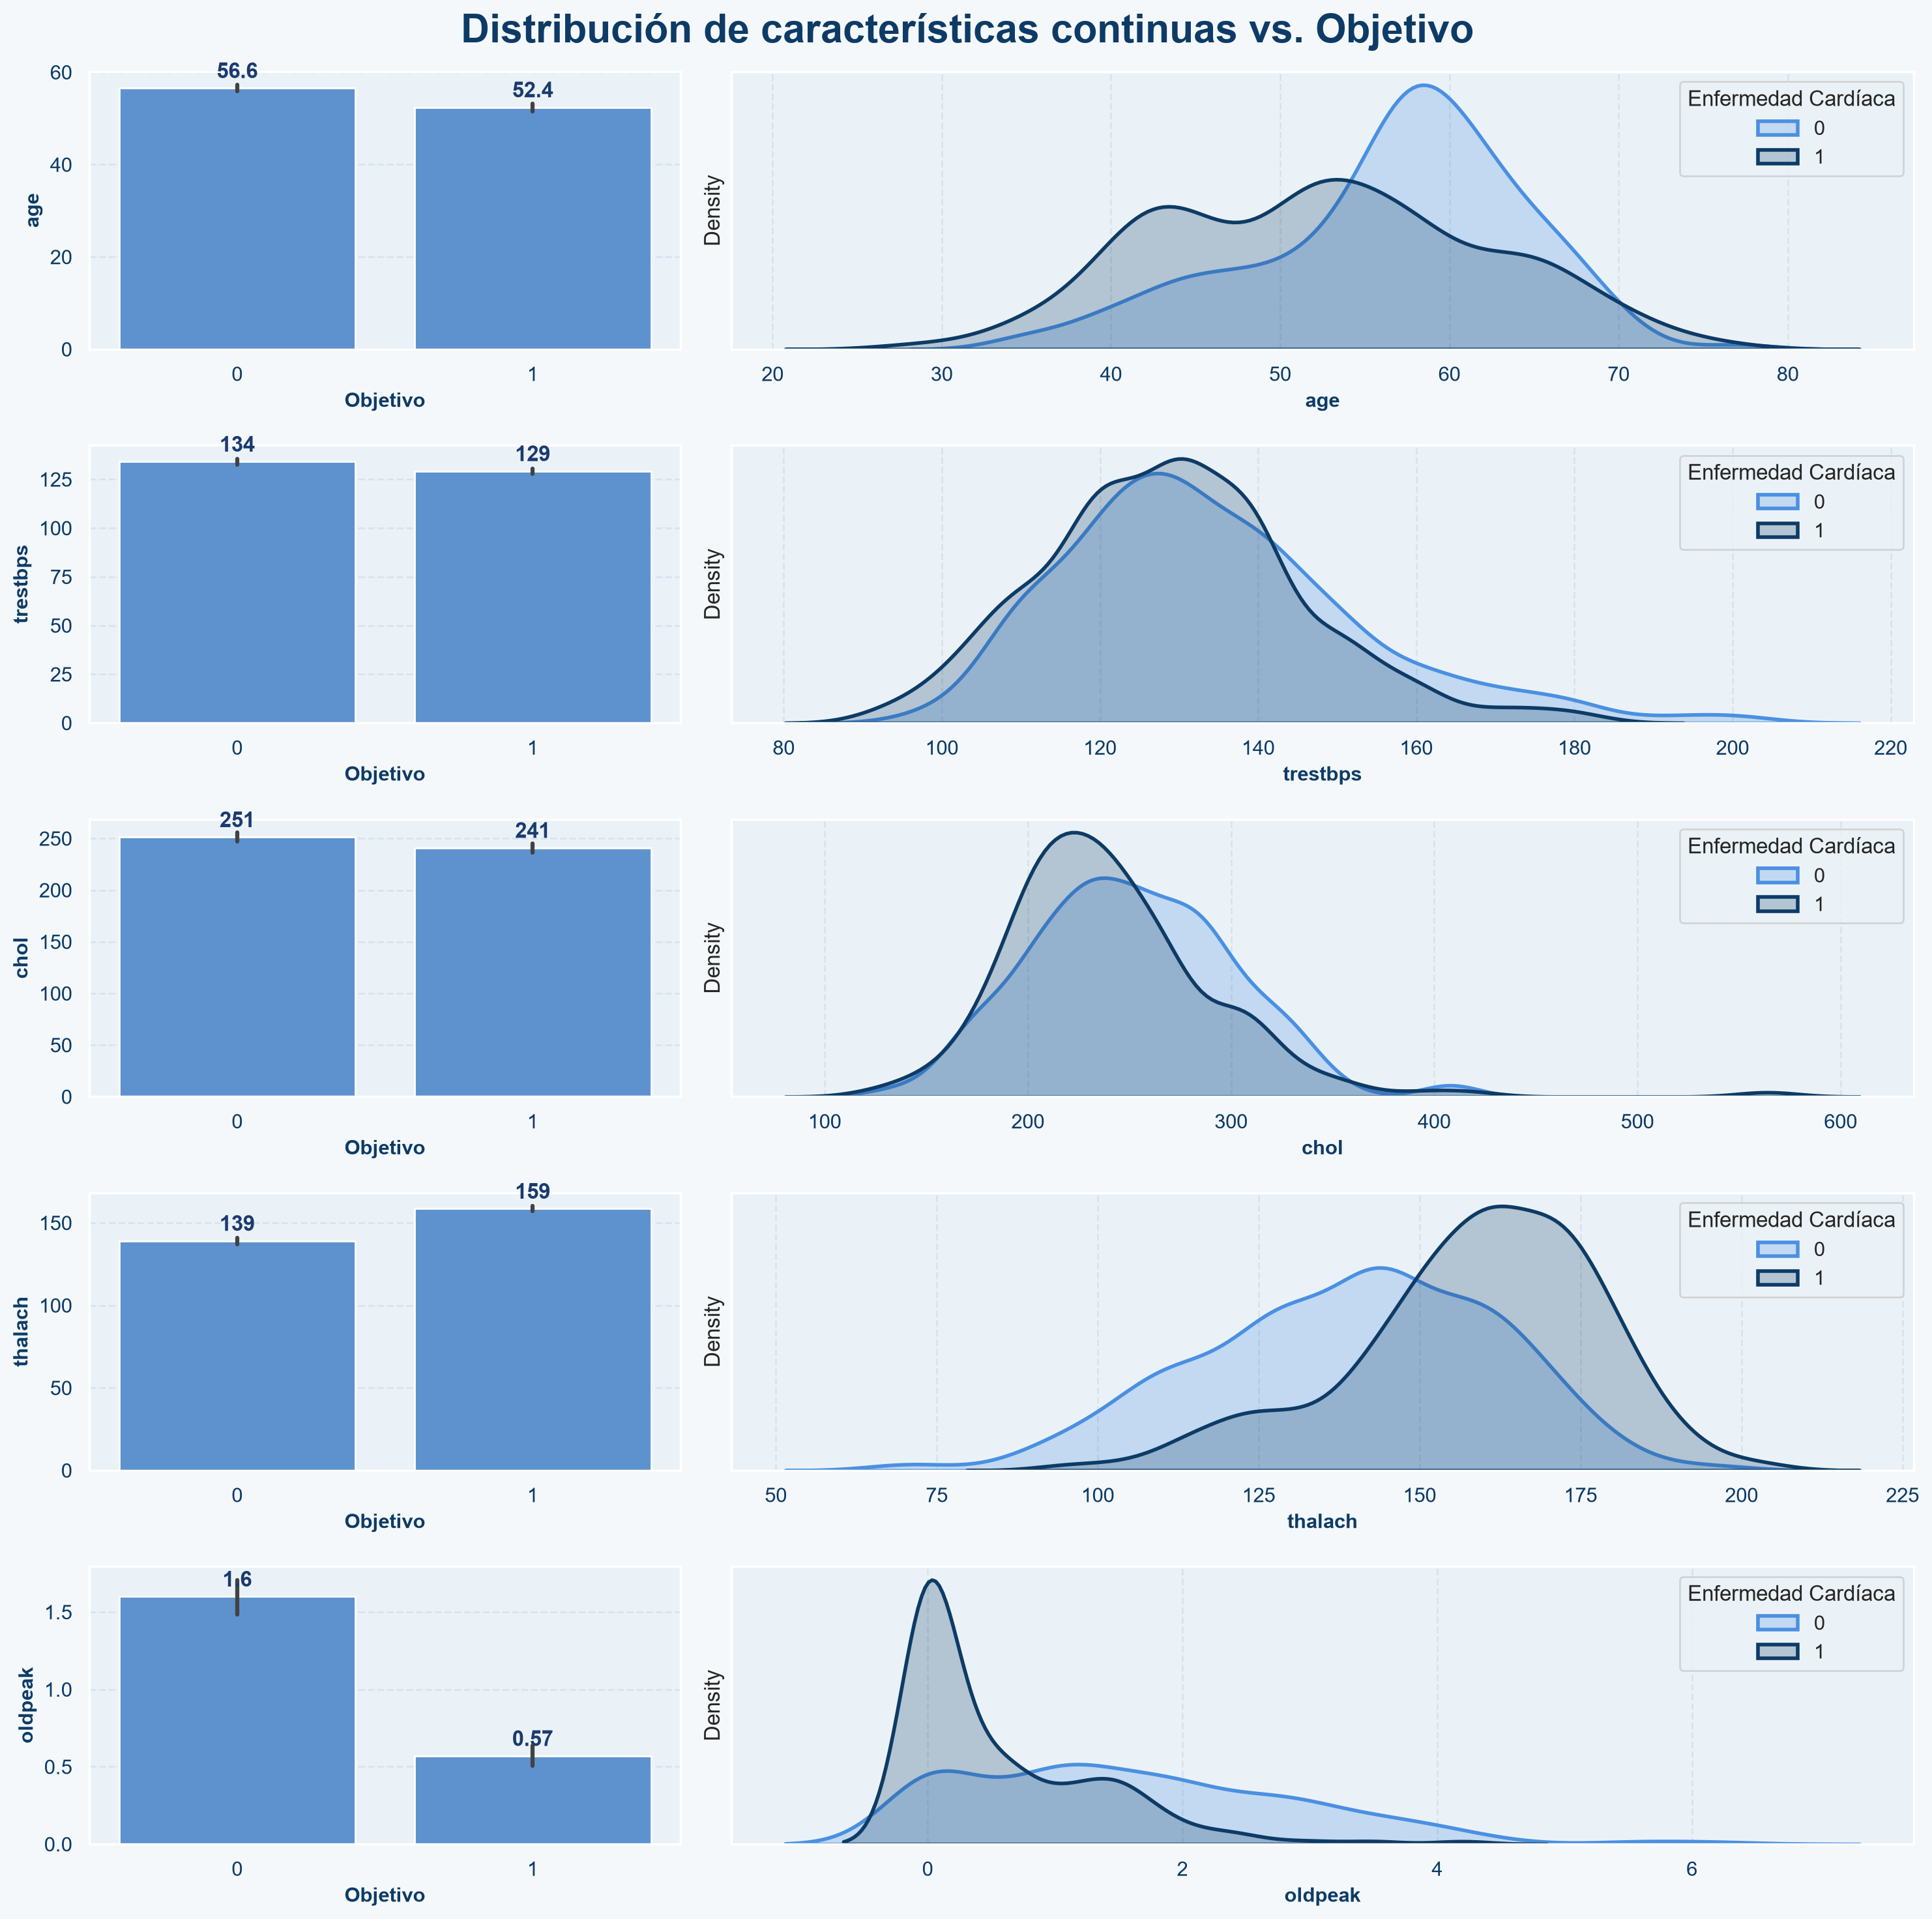

In [10]:
# Establecer la paleta de colores (usando los tonos azules clínicos)
sns.set_palette(['#4A90E2', '#0D3B66'])

# Crear los subgráficos
fig, ax = plt.subplots(len(caracteristicas_continuas), 2, figsize=(15, 15), gridspec_kw={'width_ratios': [1, 2]})

# Aplicar color de fondo a la figura completa
fig.patch.set_facecolor('#F4F8FA')

# Iterar a través de cada característica continua para crear gráficos de barras y gráficos KDE
for i, col in enumerate(caracteristicas_continuas):
    # Gráfico de barras que muestra el valor promedio de la característica para cada categoría objetivo
    grafico = sns.barplot(data=df, x="target", y=col, ax=ax[i, 0])
    
    # Gráfico KDE que muestra la distribución de la característica para cada categoría objetivo
    sns.kdeplot(data=df[df["target"] == 0], x=col, fill=True, linewidth=2, ax=ax[i, 1], label='0')
    sns.kdeplot(data=df[df["target"] == 1], x=col, fill=True, linewidth=2, ax=ax[i, 1], label='1')
    
    # Configurar colores de fondo para los ejes
    ax[i, 0].set_facecolor('#EBF2F7')
    ax[i, 1].set_facecolor('#EBF2F7')
    
    # Configurar cuadrícula
    ax[i, 0].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7, axis='y')
    ax[i, 1].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7)
    
    # Estilizar etiquetas de ejes
    ax[i, 0].set_xlabel('Objetivo', fontsize=11, fontweight='bold', color='#0D3B66')
    ax[i, 0].set_ylabel(col, fontsize=11, fontweight='bold', color='#0D3B66')
    ax[i, 1].set_xlabel(col, fontsize=11, fontweight='bold', color='#0D3B66')
    
    # Ocultar ticks en el eje Y para el KDE, pero mantener el color en el eje X
    ax[i, 1].set_yticks([])
    ax[i, 0].tick_params(colors='#0D3B66')
    ax[i, 1].tick_params(colors='#0D3B66')
    
    # Configurar la leyenda
    ax[i, 1].legend(title='Enfermedad Cardíaca', loc='upper right')
    
    # Añadir valores promedio al gráfico de barras
    for cont in grafico.containers:
        grafico.bar_label(cont, fmt='%.3g', color='#1B3B6F', fontweight='bold', padding=3)

# Establecer el título para toda la figura
plt.suptitle('Distribución de características continuas vs. Objetivo', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

### Observaciones:
* **Edad (`age`):** Las distribuciones muestran un ligero desplazamiento; en promedio, los pacientes con enfermedad cardíaca son un poco más jóvenes que aquellos sin ella. La edad promedio de los pacientes sin enfermedad cardíaca es mayor.
* **Presión arterial en reposo (`trestbps`):** Ambas categorías muestran distribuciones superpuestas en el gráfico KDE, con valores promedio casi idénticos, lo que indica un poder de diferenciación limitado para esta característica.
* **Colesterol sérico (`chol`):** Las distribuciones de los niveles de colesterol para ambas categorías son bastante cercanas, pero el nivel promedio de colesterol en los pacientes con enfermedad cardíaca es ligeramente menor.
* **Frecuencia cardíaca máxima alcanzada (`thalach`):** Hay una diferencia notable en las distribuciones. Los pacientes con enfermedad cardíaca tienden a alcanzar una frecuencia cardíaca máxima más alta durante las pruebas de esfuerzo en comparación con aquellos que no la padecen.
* **Depresión del segmento ST (`oldpeak`):** La depresión del segmento ST inducida por el ejercicio en relación con el reposo es notablemente menor para los pacientes con enfermedad cardíaca. Su distribución tiene un pico cerca de cero, mientras que la categoría sin enfermedad presenta una dispersión más amplia.

Basándose en la diferencia visual de las distribuciones y los valores promedio, la **Frecuencia cardíaca máxima (`thalach`)** parece tener el mayor impacto sobre la presencia de enfermedad cardíaca, seguida por la **Depresión del segmento ST (`oldpeak`)** y la **Edad (`age`)**.

### 4.2.2 | Características categóricas vs. Objetivo

Se mostrarán gráficos de barras apiladas al 100% para cada característica categórica, ilustrando la proporción de cada categoría en las dos clases objetivo, complementados con los conteos exactos y porcentajes en las barras.

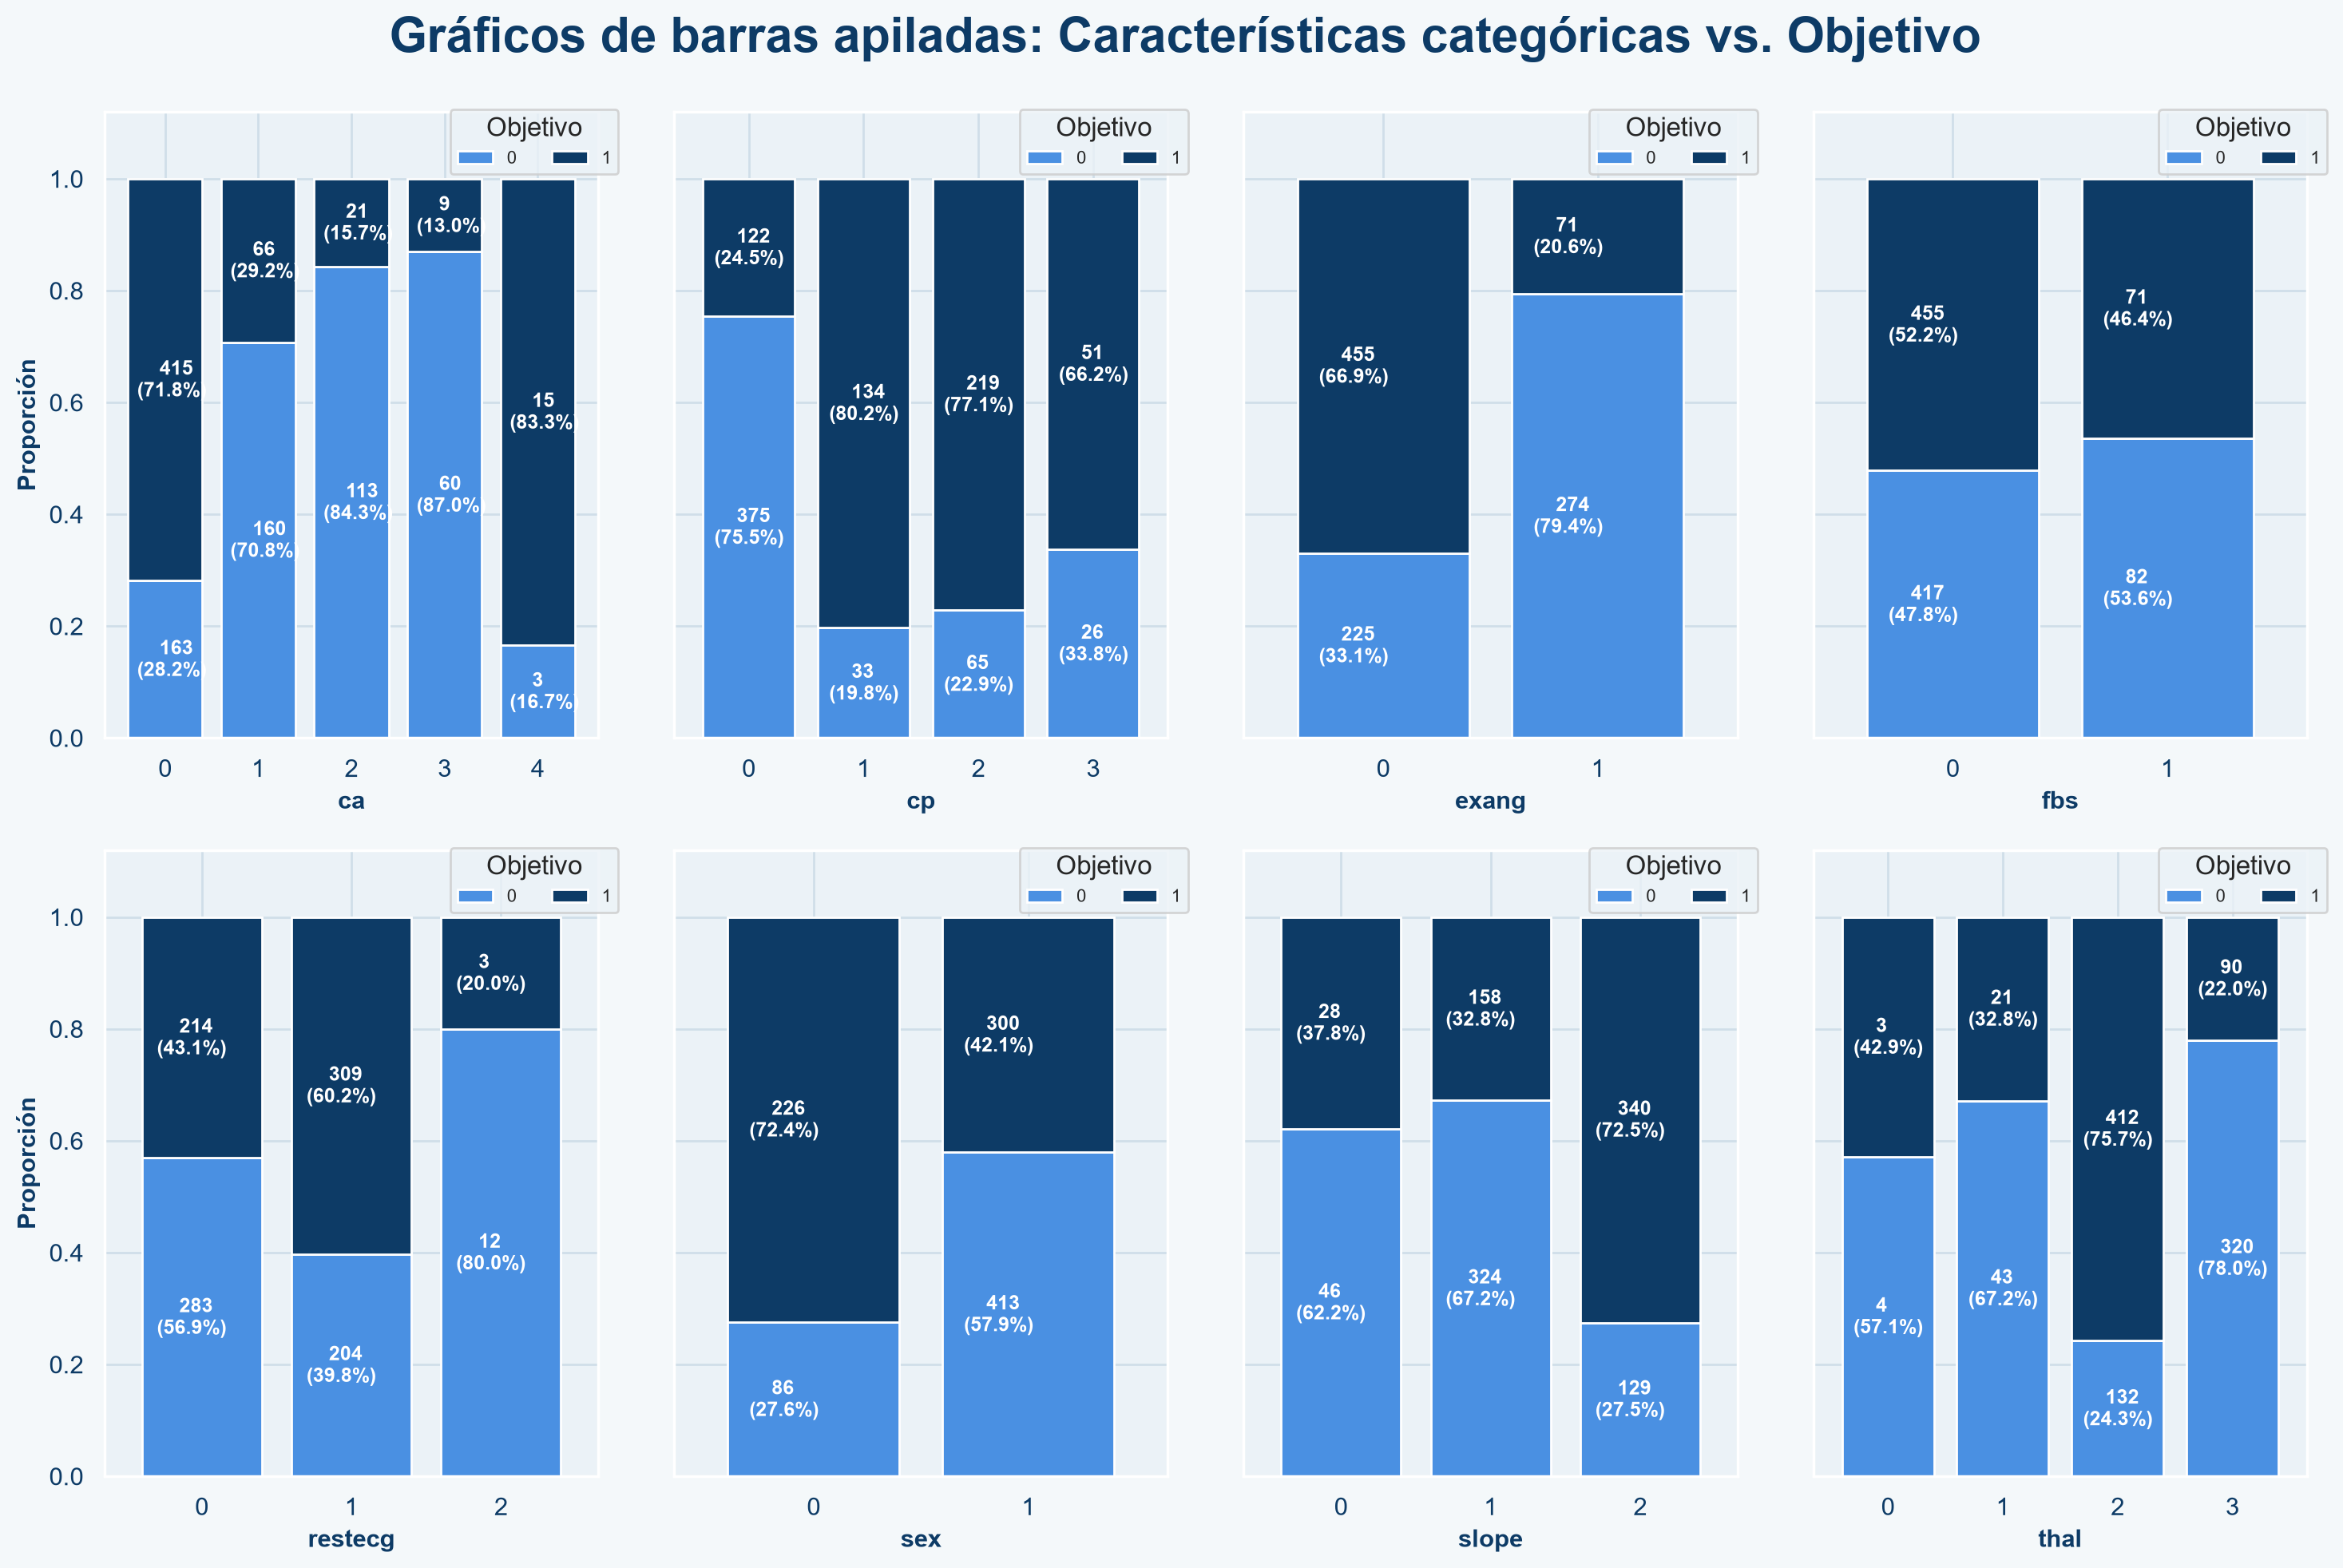

In [11]:
# Eliminar 'target' de las caracteristicas_categoricas
caracteristicas_categoricas = [caracteristica for caracteristica in caracteristicas_categoricas if caracteristica != 'target']

fig, ax = plt.subplots(nrows=2, ncols=4, figsize=(15, 10))

# Aplicar color de fondo a la figura completa
fig.patch.set_facecolor('#F4F8FA')

for i, col in enumerate(caracteristicas_categoricas):
    
    # Crear una tabla cruzada que muestre la proporción de cada categoría de la característica con respecto al objetivo
    tabla_cruzada = pd.crosstab(index=df[col], columns=df['target'])
    
    # Usar el argumento normalize='index' nos da la proporción de los datos por índice
    tabla_cruzada_prop = pd.crosstab(index=df[col], columns=df['target'], normalize='index')

    # Definir mapa de colores con la paleta clínica (azul clínico intermedio y azul marino profundo)
    cmp = ListedColormap(['#4A90E2', '#0D3B66'])
    
    # Graficar gráficos de barras apiladas
    x, y = i // 4, i % 4
    tabla_cruzada_prop.plot(kind='bar', ax=ax[x, y], stacked=True, width=0.8, colormap=cmp,
                            legend=False, ylabel='Proporción', sharey=True)
    
    # Configurar colores de fondo y estilo de ejes
    ax[x, y].set_facecolor('#EBF2F7')
    ax[x, y].set_xlabel(col, fontsize=11, fontweight='bold', color='#0D3B66')
    ax[x, y].tick_params(colors='#0D3B66')
    
    if y == 0:
        ax[x, y].set_ylabel('Proporción', fontsize=11, fontweight='bold', color='#0D3B66')
    else:
        ax[x, y].set_ylabel('')

    # Añadir las proporciones y conteos de las barras individuales a nuestro gráfico
    for idx, val in enumerate([*tabla_cruzada.index.values]):
        for (proporcion, conteo, y_location) in zip(tabla_cruzada_prop.loc[val], tabla_cruzada.loc[val], tabla_cruzada_prop.loc[val].cumsum()):
            # Se utiliza texto blanco para un mejor contraste sobre los tonos azules
            ax[x, y].text(x=idx - 0.3, y=(y_location - proporcion) + (proporcion / 2) - 0.03,
                         s=f'    {conteo}\n({np.round(proporcion * 100, 1)}%)', 
                         color="white", fontsize=9, fontweight="bold")
    
    # Añadir leyenda
    ax[x, y].legend(title='Objetivo', loc=(0.7, 0.9), fontsize=8, ncol=2)
    # Establecer límite del eje y
    ax[x, y].set_ylim([0, 1.12])
    # Rotar etiquetas del eje x
    ax[x, y].set_xticklabels(ax[x, y].get_xticklabels(), rotation=0)

# Títulos y ajustes finales de la figura
plt.suptitle('Gráficos de barras apiladas: Características categóricas vs. Objetivo', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.92) # Ajuste adicional para que el título principal no se superponga
plt.show()

### Observaciones:
* **Número de vasos principales (ca):** La mayoría de los pacientes con enfermedad cardíaca tienen menos vasos principales coloreados por fluoroscopia. A medida que aumenta el número de vasos coloreados, la proporción de pacientes con enfermedad cardíaca tiende a disminuir. En particular, los pacientes con 0 vasos coloreados tienen una mayor proporción de presencia de enfermedad cardíaca.
* **Tipo de dolor en el pecho (cp):** Diferentes tipos de dolor en el pecho presentan proporciones variadas de enfermedad cardíaca. Notablemente, los tipos 1, 2 y 3 tienen una mayor proporción de presencia de enfermedad cardíaca en comparación con el tipo 0. Esto sugiere que el tipo de dolor en el pecho puede ser influyente en la predicción de la enfermedad.
* **Angina inducida por el ejercicio (exang):** Los pacientes que no experimentaron angina inducida por el ejercicio (0) muestran una mayor proporción de presencia de enfermedad cardíaca en comparación con aquellos que sí lo hicieron (1). Esta característica parece tener un impacto significativo en la variable objetivo.
* **Azúcar en sangre en ayunas (fbs):** La distribución entre aquellos con azúcar en sangre en ayunas > 120 mg/dl (1) y aquellos que no la tienen (0) es relativamente similar, lo que sugiere que `fbs` podría tener un impacto limitado en la predicción de la enfermedad cardíaca.
* **Resultados electrocardiográficos en reposo (restecg):** El tipo 1 muestra una mayor proporción de presencia de enfermedad cardíaca, lo que indica que esta característica podría tener cierta influencia en el resultado.
* **Sexo (sex):** Las mujeres (1) exhiben una menor proporción de presencia de enfermedad cardíaca en comparación con los hombres (0). Esto indica que el sexo es un factor influyente en la predicción de la enfermedad cardíaca.
* **Pendiente del segmento ST máximo durante el ejercicio (slope):** El tipo de pendiente 2 tiene una proporción notablemente mayor de presencia de enfermedad cardíaca, lo que indica su potencial como un predictor significativo.
* **Resultado de la prueba de esfuerzo con talio (thal):** La categoría de defecto reversible (2) tiene una mayor proporción de presencia de enfermedad cardíaca en comparación con las otras categorías, enfatizando su importancia en la predicción.

En resumen, basándose en la representación visual:
* **Mayor impacto en el objetivo:** ca, cp, exang, sex, slope y thal.
* **Impacto moderado en el objetivo:** restecg.
* **Menor impacto en el objetivo:** fbs.